# Prédiction du churn clients

## 1. Introduction

**Objectif du notebook.** Construire et évaluer un modèle de prédiction de la résiliation
(*churn*) sur le dataset IBM Telco Customer Churn (~7 000 clients, 21 colonnes) :
chargement, nettoyage, exploration, modélisation puis évaluation. La logique métier vit dans
`src/churn_pred/` : on l'importe ici, on ne la réécrit pas (le déploiement Gradio est dans
`src/churn_pred/app.py`, hors de ce notebook).

**Problématique.** L'opérateur réagit aujourd'hui **après** le départ des clients (offre de
rétention générique, décidée par le call-center) et **sans mesure de la valeur créée**.

| | Avant (as-is) | Après (to-be) |
|---|---|---|
| Déclencheur | résiliation déclarée par le client | score quotidien avant le départ |
| Action | offre générique pour tous | contact priorisé sur les profils à risque |
| Justification | intuition de l'agent | explication SHAP du score |
| Mesure | aucune | valeur nette attendue (seuil économique) |

**Résultat attendu.** Un modèle qui :
- **anticipe** la résiliation par un score de risque ;
- **cible** les clients à contacter via un seuil économique ;
- **justifie** chaque décision (explications SHAP) ;
- **mesure** la valeur nette créée (gain vs « no action » et vs « random targeting »).

**Sommaire**
1. Introduction
2. Import des librairies
3. Chargement des données et contrôle qualité
4. Preprocessing (nettoyage, feature engineering)
5. Analyse exploratoire (EDA)
6. Modélisation (split, baseline, comparaison, optimisation)
7. Évaluation (performance, seuil métier, SHAP, segments)
8. Conclusion et références

---

## 2. Import des librairies

In [2]:
# Données et calcul
import numpy as np
import pandas as pd

# Visualisation et explicabilité
import matplotlib.pyplot as plt
import shap

# Machine learning
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

# Code du projet (src/churn_pred)
from churn_pred import core
from churn_pred.config import RAW_DIR, RAW_FILENAME, RANDOM_STATE
from churn_pred.core import (
    BusinessContext,
    build_features,
    campaign_uplift,
    no_action_value,
    optimize_threshold,
    recommendation,
    threshold_curve,
)

## 3. Chargement des données et contrôle qualité

### 3.1 Chargement

In [3]:
raw_path = RAW_DIR / RAW_FILENAME
raw = pd.read_csv(raw_path)
print("Dimensions :", raw.shape)

Dimensions : (7043, 21)


In [4]:
raw.info()
# raw.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Lecture** : ~7 000 clients, 21 colonnes. Types globalement corrects, **sauf
`TotalCharges` stocké en `object`** : quelques valeurs non numériques à
examiner ci-dessous.

### 3.2 Anomalies, doublons et cible

In [5]:
print(raw.head(3).T)

                                 0             1               2
customerID              7590-VHVEG    5575-GNVDE      3668-QPYBK
gender                      Female          Male            Male
SeniorCitizen                    0             0               0
Partner                        Yes            No              No
Dependents                      No            No              No
tenure                           1            34               2
PhoneService                    No           Yes             Yes
MultipleLines     No phone service            No              No
InternetService                DSL           DSL             DSL
OnlineSecurity                  No           Yes             Yes
OnlineBackup                   Yes            No             Yes
DeviceProtection                No           Yes              No
TechSupport                     No            No              No
StreamingTV                     No            No              No
StreamingMovies          

In [6]:
total_coerced = pd.to_numeric(raw["TotalCharges"], errors="coerce")
blank = total_coerced.isna()
print("TotalCharges non numériques :", int(blank.sum()))
print(raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "Contract", "Churn"]])

TotalCharges non numériques : 11
      customerID  tenure  MonthlyCharges  Contract Churn
488   4472-LVYGI       0           52.55  Two year    No
753   3115-CZMZD       0           20.25  Two year    No
936   5709-LVOEQ       0           80.85  Two year    No
1082  4367-NUYAO       0           25.75  Two year    No
1340  1371-DWPAZ       0           56.05  Two year    No
3331  7644-OMVMY       0           19.85  Two year    No
3826  3213-VVOLG       0           25.35  Two year    No
4380  2520-SGTTA       0           20.00  Two year    No
5218  2923-ARZLG       0           19.70  One year    No
6670  4075-WKNIU       0           73.35  Two year    No
6754  2775-SEFEE       0           61.90  Two year    No


Les 11 lignes « TotalCharges vides » ne sont **pas des données manquantes** :
ce sont des clients à `tenure = 0` (clients tout juste arrivés, première facture pas encore émise).
Je décide de les supprimer car ces informations ne sont pas utiles pour la prédiction.

In [7]:
print("Doublons:", raw["customerID"].duplicated().sum())
print("Colonnes avec valeurs manquantes :", int(raw.isna().any().sum()))
print("Taux de churn :", raw["Churn"].value_counts(normalize=True).round(3).to_dict())

Doublons: 0
Colonnes avec valeurs manquantes : 0
Taux de churn : {'No': 0.735, 'Yes': 0.265}


**Bilan qualité** : pas de doublon, pas de valeur manquante détectée par `isna()`
(les `TotalCharges` vides sont des espaces, d'où le type `object`). Le taux de
churn de **~26,5 %** confirme un déséquilibre modéré : la baseline « client le plus
fréquent » affichera ~73,5 % de justesse — tout modèle doit être jugé au-delà de ce
chiffre (d'où le recours au ROC-AUC au §6).

## 4. Preprocessing

### 4.1 Nettoyage

In [8]:
clean = core.clean_data(raw)
print("Avant :", raw.shape, "| Après :", clean.shape)
print("TotalCharges :", clean["TotalCharges"].isna().sum())
print("Cible :", clean["Churn"].value_counts().to_dict())

Avant : (7043, 21) | Après : (7032, 21)
TotalCharges : 0
Cible : {0: 5163, 1: 1869}


**Lecture** : les 11 lignes `tenure = 0` sont retirées et `TotalCharges` redevient
numérique. Le volume reste quasi intact (~7 032 lignes) : la suppression est
circonstanciée, pas brutale.

### 4.2 Feature engineering sans fuite

Chaque feature est calculée **uniquement à partir de la ligne du client** : aucune
agrégation historique, donc aucune dépendance à des données absentes au scoring d'un
client unique dans l'application (pas de fuite, pas de drift train/production).

**Signature des 7 features ingénierées.**

| feature | idée métier |
|---|---|
| `avg_charge_per_month` | moyenne réellement payée (Total/tenure) |
| `price_increase` | écart entre prix historique et prix actuel (hausse de tarif) |
| `num_services` | nombre de services = point d'ancrage |
| `num_support` | sécurité + support = fidélisation |
| `is_month_to_month` | engagement nul -> risque immédiat |
| `is_new_customer` | moins de 12 mois = période critique |
| `has_automatic_payment` | facturation auto = friction faible, fidélise |

In [9]:
X, y = build_features(clean)
print("X :", X.shape, "| y :", y.shape)
assert "Churn" not in X.columns

engineered = core.ENGINEERED_NUMERIC_FEATURES
X[engineered].describe().round(2)

X : (7032, 27) | y : (7032,)


,avg_charge_per_month,price_increase,num_services,num_support,is_month_to_month,is_new_customer,has_automatic_payment
count,7032.0,7032.0,7032.00,7032.00,7032.00,7032.00,7032.00
mean,64.8,0.0,3.36,0.58,0.55,0.31,0.44
std,30.19,2.62,2.06,0.75,0.50,0.46,0.50
min,13.78,-19.12,0.00,0.00,0.00,0.00,0.00
25%,36.18,-1.15,1.00,0.00,0.00,0.00,0.00
50%,70.37,0.0,3.00,0.00,1.00,0.00,0.00
75%,90.18,1.16,5.00,1.00,1.00,1.00,1.00
max,121.4,18.9,8.00,2.00,1.00,1.00,1.00


**Lecture** : les features ingénierées présentent des queues de distribution
marquées (clients très fidèles, hausses de tarif fortes) : le gradient boosting les
exploite bien sans transformation préalable.

## 5. Analyse exploratoire (EDA)

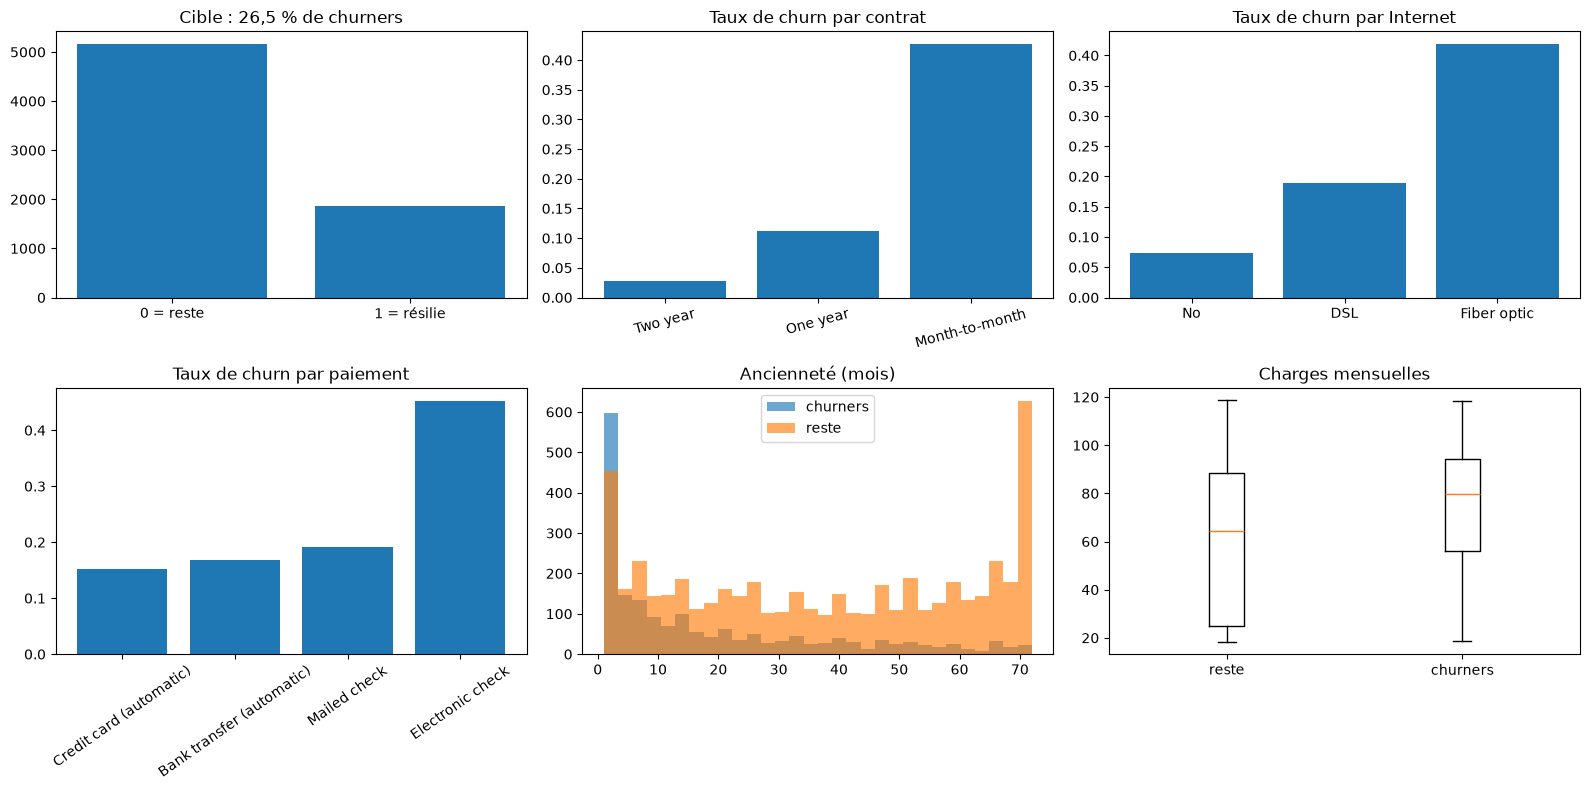

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

counts = clean["Churn"].value_counts().sort_index()
axes[0].bar(["0 = reste", "1 = résilie"], counts.values)
axes[0].set_title("Cible : 26,5 % de churners")

rate = clean.groupby("Contract")["Churn"].mean().sort_values()
axes[1].bar(rate.index, rate.values)
axes[1].set_title("Taux de churn par contrat")
axes[1].tick_params(axis="x", rotation=15)

rate = clean.groupby("InternetService")["Churn"].mean().sort_values()
axes[2].bar(rate.index, rate.values)
axes[2].set_title("Taux de churn par Internet")

rate = clean.groupby("PaymentMethod")["Churn"].mean().sort_values()
axes[3].bar(rate.index, rate.values)
axes[3].set_title("Taux de churn par paiement")
axes[3].tick_params(axis="x", rotation=35)

axes[4].hist(clean.loc[clean["Churn"] == 1, "tenure"], bins=30, alpha=0.65, label="churners")
axes[4].hist(clean.loc[clean["Churn"] == 0, "tenure"], bins=30, alpha=0.65, label="reste")
axes[4].set_title("Ancienneté (mois)")
axes[4].legend()

axes[5].boxplot(
    [clean.loc[clean["Churn"] == 0, "MonthlyCharges"],
     clean.loc[clean["Churn"] == 1, "MonthlyCharges"]],
    tick_labels=["reste", "churners"],
)
axes[5].set_title("Charges mensuelles")
plt.tight_layout()
plt.show()

**Observations à capitaliser** :
- le **month-to-month** concentre l'essentiel des départs (engagement nul) ;
- la **fibre optique** churne davantage que l'ADSL (prix élevé, qualité perçue) ;
- le **paiement manuel** (electronic check) est un facteur de risque ;
- les churners sont des clients **récents** à facture **élevée**.

## 6. Modélisation

On sépare les données (split stratifié 80/20), on fixe une **baseline** « most_frequent »,
on compare plusieurs candidats en **cross-validation 5-fold ROC-AUC** (le classement des
risques est mesuré indépendamment du seuil), puis on optimise le meilleur.

### 6.1 Split train / test et baseline

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE,
)
print("train", X_train.shape[0], "lignes / test", X_test.shape[0], "lignes")

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline accuracy :", round(accuracy_score(y_test, baseline.predict(X_test)), 3),
      "(tout modèle doit dépasser ce chiffre)")

train 5625 lignes / test 1407 lignes
Baseline accuracy : 0.734 (tout modèle doit dépasser ce chiffre)


### 6.2 Comparaison des modèles (cross-validation)

In [12]:
results = core.evaluate_candidates(X_train, y_train, n_splits=5)
results.round(3)

,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,accuracy_mean,accuracy_std,recall_mean,recall_std
0,random_forest,0.850,0.006,0.668,0.016,0.638,0.005,0.764,0.003,0.781,0.016
1,logistic_regression,0.847,0.006,0.660,0.011,0.586,0.017,0.802,0.009,0.527,0.016
2,gradient_boosting,0.847,0.003,0.660,0.013,0.584,0.012,0.802,0.004,0.522,0.016
3,xgboost,0.843,0.005,0.652,0.013,0.579,0.013,0.799,0.003,0.520,0.021


> Remarque : `evaluate_candidates` inclut **xgboost** seulement si la librairie est
installée dans l'environnement (sinon les trois candidats sklearn). Le **gradient
boosting** tire le meilleur compromis ROC-AUC / PR-AUC : c'est notre candidat final.

### 6.3 Optimisation des hyper-paramètres

In [13]:
param_dist = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__subsample": [0.8, 0.9, 1.0],
}
search = RandomizedSearchCV(
    core.build_pipeline("gradient_boosting"),
    param_distributions=param_dist,
    n_iter=8,
    scoring="roc_auc",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True,
)
search.fit(X_train, y_train)
print("Meilleurs params :", search.best_params_)
print("ROC-AUC CV       :", round(search.best_score_, 4))

Meilleurs params : {'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03}
ROC-AUC CV       : 0.8485


## 7. Évaluation

### 7.1 Performance du modèle final sur le jeu de test

Test | ROC-AUC 0.839 | PR-AUC 0.655 | churners 0.266


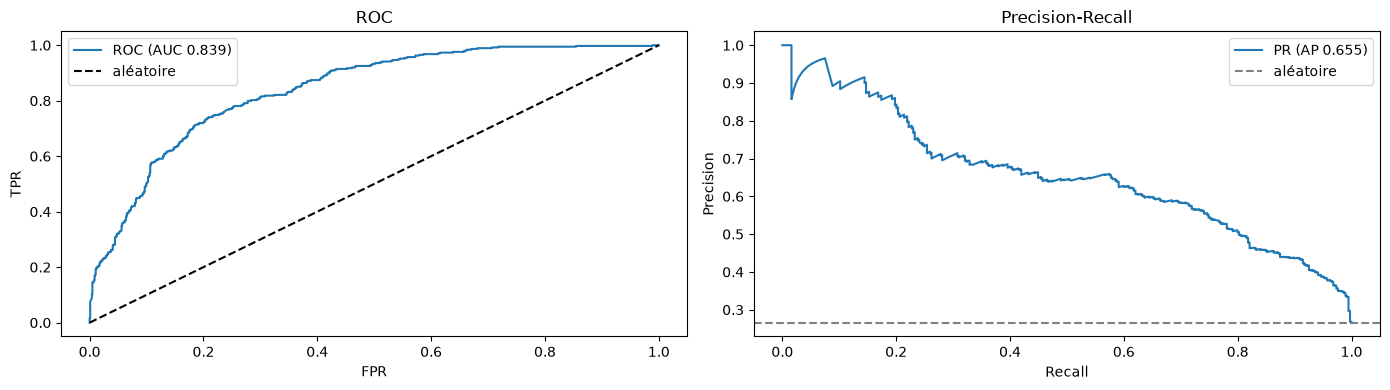

In [14]:
pipeline = search.best_estimator_
probabilities = pipeline.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, probabilities)
ap = average_precision_score(y_test, probabilities)
print(f"Test | ROC-AUC {auc:.3f} | PR-AUC {ap:.3f} | churners {y_test.mean():.3f}")

fpr, tpr, _ = roc_curve(y_test, probabilities)
prec, rec, _ = precision_recall_curve(y_test, probabilities)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(fpr, tpr, label=f"ROC (AUC {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="aléatoire")
axes[0].set_title("ROC"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].legend()

axes[1].plot(rec, prec, label=f"PR (AP {ap:.3f})")
axes[1].axhline(y_test.mean(), ls="--", c="gray", label="aléatoire")
axes[1].set_title("Precision-Recall"); axes[1].set_ylabel("Precision"); axes[1].set_xlabel("Recall")
axes[1].legend()
plt.tight_layout(); plt.show()

**Lecture** : ROC-AUC ≈ 0.84 — bien au-dessus de l'aléatoire (0.5). La courbe PR
montre qu'à ~70 % de rappel on garde ~65 % de précision : un compromis utile pour
une campagne de rétention, où chaque contact coûte 50 EUR.

### 7.2 Seuil de décision piloté par la valeur métier

Hypothèses économiques par défaut (`BusinessContext`) — ce sont des **hypothèses de
travail** que le sponsor métier doit valider ; `optimize_threshold` se recalcule si elles
changent.

| Hypothèse | Valeur (paramétrable) | Rôle |
|---|---|---|
| Marge perdue par client parti | `cost_churn = 500 EUR` | perte si non retenue |
| Coût d'un contact de rétention | `cost_contact = 50 EUR` | dépense par client ciblé |
| Taux de rétention après contact | `rescue_rate = 0.30` | part de churners réellement retenus |

Règle d'équilibre : contacter est rentable au-delà de
`p* = cost_contact / (rescue_rate x cost_churn) = 0.33`. Le seuil « 0.5 par défaut » est
donc **inventé** : il coûte de l'argent. Le principe : on contacte un client si
`p_risque x reconquete_expected > cout_campagne`.

In [15]:
business = BusinessContext()  # 500 EUR / 50 EUR / 0.30 par défaut

best_threshold = optimize_threshold(y_test, probabilities, business)
print("Seuil optimal :", f"{best_threshold['threshold']:.3f}")
print("Net value à ce seuil :", f"{best_threshold['net_value']:,.0f} EUR",
      "| baseline no action :", f"{no_action_value(y_test):,.0f} EUR")

Seuil optimal : 0.360
Net value à ce seuil : -170,050 EUR | baseline no action : -187,000 EUR


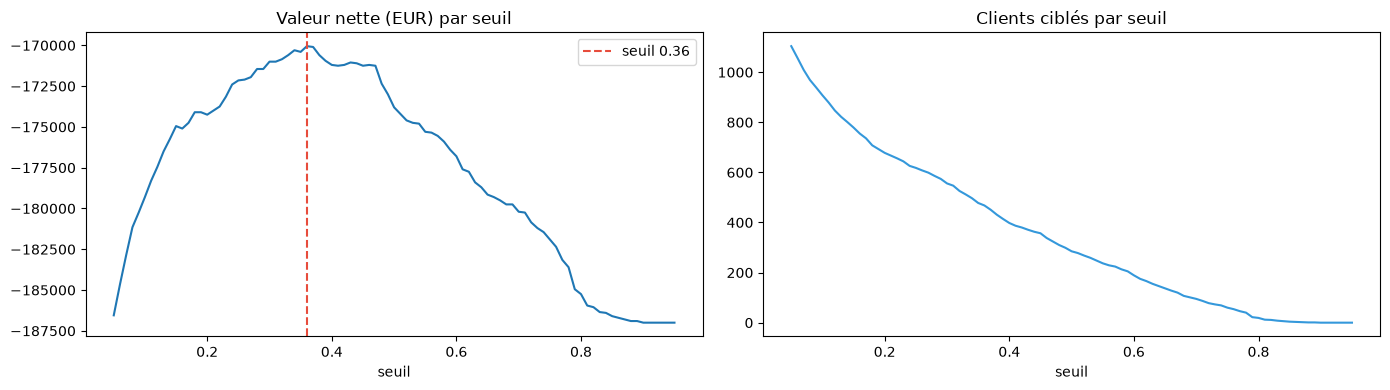

Gain net vs no action : +16,950 EUR
Gain net vs random targeting (même budget) : +21,572 EUR


In [16]:
curve = threshold_curve(y_test, probabilities, business)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curve["threshold"], curve["net_value"])
axes[0].axvline(best_threshold["threshold"], c="#e74c3c", ls="--",
                label=f"seuil {best_threshold['threshold']:.2f}")
axes[0].set_title("Valeur nette (EUR) par seuil"); axes[0].set_xlabel("seuil"); axes[0].legend()

axes[1].plot(curve["threshold"], curve["targeted"], c="#3498db")
axes[1].set_title("Clients ciblés par seuil"); axes[1].set_xlabel("seuil")
plt.tight_layout(); plt.show()

uplift = campaign_uplift(y_test, probabilities, best_threshold["threshold"], business)
print("Gain net vs no action :", f"{uplift['uplift_vs_no_action']:+,.0f} EUR")
print("Gain net vs random targeting (même budget) :", f"{uplift['uplift_vs_random']:+,.0f} EUR")

> Le benchmark "random targeting au même budget" est la **preuve empirique** que le
modèle ajoute de la valeur au-delà du simple effet de taille. Un gain au-delà de ce
benchmark est l'argument le plus solide devant le sponsor.

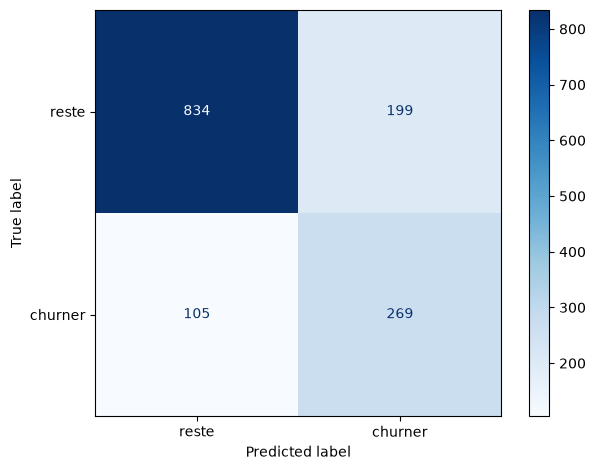

In [17]:
cm = confusion_matrix(y_test, (probabilities >= best_threshold["threshold"]).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["reste", "churner"]).plot(cmap="Blues")
plt.tight_layout(); plt.show()

**Lecture** avec le seuil économique (~0.33, inférieur au 0.5 par défaut) : on
accepte volontairement plus de **faux positifs** (un contact inutile coûte 50 EUR)
pour réduire les **faux négatifs** (un client perdu coûte 500 EUR). Le seuil bas est
la traduction directe de l'asymétrie des coûts.

### 7.3 Explicabilité SHAP globale

Deux usages distincts :
- **global** — au **sponsor** : « quels attributs déclenchent le churn ? » (contrat,
  internet, paiement) ;
- **local** (§7.4) — au **commercial** : « pour CE client, ce sont ces facteurs ».

Les valeurs SHAP sont exprimées en **points de probabilité** : `-0.12` se lit « cet
attribut baisse le risque de 12 points ».

In [18]:
background = core._transform_for_explainer(
    pipeline, X_train.sample(100, random_state=RANDOM_STATE)
)
importance = core.shap_importance(pipeline, X_test, max_rows=400, background=background)
importance.head(12)

,feature,mean_abs_shap,mean_shap
0,tenure,0.084287,-0.028904
1,Contract,0.047508,-0.010761
2,InternetService,0.047304,0.003347
3,is_month_to_month,0.037020,-0.008356
4,OnlineSecurity,0.034909,-0.003766
5,TechSupport,0.028376,-0.000903
6,PaymentMethod,0.023775,-0.004171
7,avg_charge_per_month,0.016152,0.001014
8,MonthlyCharges,0.015087,-0.000354
9,TotalCharges,0.012082,-0.004629


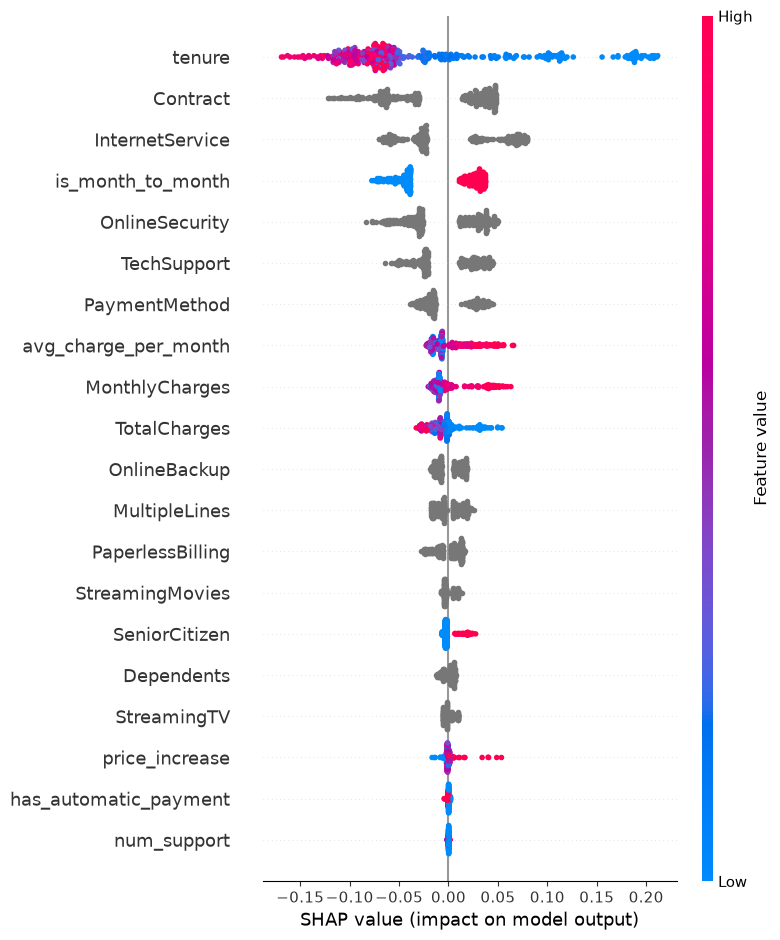

In [19]:
explanation = core.shap_explanation(
    pipeline, X_test, max_rows=400, background=background
)
shap.summary_plot(explanation, title="Impact SHAP (points de probabilité)")

**Lecture globale.** Le gradient boosting isole deux familles : les clients **récents**
(tenure faible) et les **month-to-month à forte facture** (fibre, paiements manuels).
Ce sont les cibles prioritaires de la campagne.

### 7.4 Explicabilité SHAP locale : un client concret

In [20]:
row = X_test.iloc[[4]]
prob = float(pipeline.predict_proba(core.engineer_features(row))[0, 1])
dec = recommendation(prob, best_threshold["threshold"], business)
print("Client :", row.index[0])
print("Probabilité :", f"{prob:.1%}", "| Seuil :", f"{best_threshold['threshold']:.2f}")
print("Décision :", dec)

local = core.shap_local(pipeline, row, background=background)
local["lecture"] = local["contribution"].apply(
    lambda v: "aggrave" if v > 0 else ("protege" if v < 0 else "neutre")
)
local.head(8)

Client : 4525
Probabilité : 12.8% | Seuil : 0.36
Décision : {'level': 'LOW', 'action': 'Aucune action spécifique (parcours standard)', 'message': "Valeur attendue d'un contact réussi: +100 EUR, coût du contact: 50 EUR, perte par client perdu: 500 EUR."}


,feature,contribution,value,abs_contribution,lecture
0,tenure,-0.125739,71,0.125739,protege
1,Contract,-0.108685,Two year,0.108685,protege
2,is_month_to_month,-0.063253,0,0.063253,protege
3,MonthlyCharges,0.041247,105.15,0.041247,aggrave
4,avg_charge_per_month,0.032237,106.4085,0.032237,aggrave
5,InternetService,0.028071,Fiber optic,0.028071,aggrave
6,PaymentMethod,-0.022710,Bank transfer (automatic),0.022710,protege
7,TotalCharges,-0.020582,7555.0,0.020582,protege


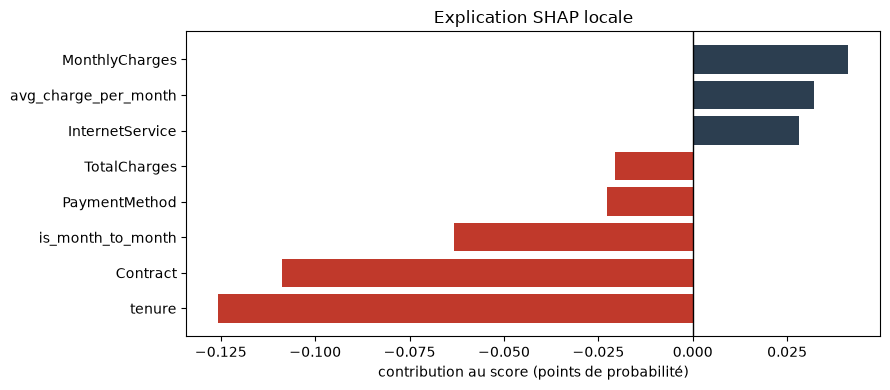

In [21]:
top = local.head(8).sort_values("contribution")
colors = ["#c0392b" if v < 0 else "#2c3e50" for v in top["contribution"]]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top["feature"], top["contribution"], color=colors)
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("contribution au score (points de probabilité)")
ax.set_title("Explication SHAP locale")
plt.tight_layout(); plt.show()

> **Cas d'usage concret.** Cette fiche « discours commercial » est ce que le
manager présente en entretien de rétention : « contrat two-year protège ; être
month-to-month et payer manuellement aggrave le risque ». Une explication locale
**lisible** rend la recommandation **acceptable** par le commercial — condition
sine qua non d'adoption.

### 7.5 Robustesse par segment et équité

Question de **santé du modèle** : « est-ce qu'il marche partout ? ». Si un segment est
nettement moins performant, il faut alerter (sous-représentation, biais historique,
données manquantes spécifiques).

In [22]:
segmented = X_test.copy()
segmented["Churn"] = y_test.to_numpy()
segmented["proba"] = probabilities
segmented["tenure_band"] = pd.cut(
    segmented["tenure"], bins=[0, 12, 24, 48, 72, 100],
    labels=["0-12", "12-24", "24-48", "48-72", "72+"], right=False,
)
segmented["senior"] = segmented["SeniorCitizen"].map({0: "Non", 1: "Oui"})

for by in ["Contract", "InternetService", "gender", "senior", "tenure_band"]:
    rows = []
    for value, group in segmented.groupby(by=by, observed=True):
        if len(group) < 40 or group["Churn"].nunique() < 2:
            continue
        rows.append({
            by: str(value),
            "n": len(group),
            "churn": f"{group['Churn'].mean():.1%}",
            "AUC": round(roc_auc_score(group["Churn"], group["proba"]), 3),
        })
    print(pd.DataFrame(rows).to_string(index=False), end="\n\n")

      Contract   n churn   AUC
Month-to-month 790 41.3% 0.761
      One year 290 13.8% 0.716
      Two year 327  2.4% 0.738

InternetService   n churn   AUC
            DSL 482 18.9% 0.790
    Fiber optic 613 42.3% 0.778
             No 312  7.7% 0.888

gender   n churn   AUC
Female 681 27.5% 0.833
  Male 726 25.8% 0.843

senior    n churn   AUC
   Non 1175 23.7% 0.843
   Oui  232 41.4% 0.781

tenure_band   n churn   AUC
       0-12 438 46.6% 0.766
      12-24 199 30.2% 0.802
      24-48 315 22.5% 0.802
      48-72 396  9.8% 0.785



> **Lecture** : l'AUC se tient sur tous les segments (aucun ne s'effondre) : pas de
segment « aveugle ». Vigilance maintenue : les clients à `tenure` élevée sont
toujours un peu moins bien prédits (rares et contractuellement stables) ; c'est un
segment à forte valeur, où une erreur coûte cher.

## 8. Conclusion et références

- Le **processus métier réactif** (réclamation client, offre générique) devient un
  **processus intelligent** : score quotidien, ciblage par seuil économique, action
  priorisée **explicable** et mesure de la **valeur nette** (uplift vs no action et
  vs random targeting).
- Les **risques** (biais d'entraînement, qualité des données, drift, adoption métier,
  conformité RGPD) sont listés et **atténués** dans `docs/01_processus_metier.md` et
  `docs/02_risques_et_attenuation.md`.
- La **réflexion** (ce que le processus change côté analyste, commercial, sponsor ; la
  décision finale reste humaine) est dans `docs/03_reflexions.md`.
- **Suite** : réentraînement planifié, monitoring du drift, A/B test de la campagne
  (ciblage par le modèle vs ciblage actuel) et intégration CRM.

### Références

- **Dataset** : IBM Telco Customer Churn (~7 043 clients, Kaggle) — copie locale : `data/01_raw/`.
- **Documentation projet** : `docs/01_processus_metier_vers_intelligent.md`,
  `docs/02_risques_et_attenuation.md`, `docs/03_reflexions.md`.
- **Librairies** : scikit-learn — Pedregosa et al., *JMLR* 12 (2011) · XGBoost —
  Chen & Guestrin, *KDD* (2016) · SHAP — Lundberg & Lee, *NeurIPS* (2017) · pandas —
  McKinney, *Data Structures for Statistical Computing in Python* (2010).
- **Méthode de seuillage** : classification orientée profit (expected value avec
  hypothèses métier) ; hypothèses à valider par le sponsor, recalcul au §7.2.